Import Libraries

In [1]:
from pathlib import Path
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_fscore_support,
    cohen_kappa_score,
)

Configuration and coding rules

In [2]:
# In a notebook, use the current working directory instead of __file__.
BASE_DIR = Path.cwd()

# Change to .xlsx if you have converted the CSV into an Excel workbook.
DATA_PATH = BASE_DIR / "transparency-reports-export.csv"

OUTPUT_DIR = BASE_DIR / "outputs"
SEED = 42

REQUIRED_COLUMNS = [
    "Organization",
    "Country",
    "Reporting Period",
    "Publication Date",
    "Question Title",
    "Answer Text",
]

DIMENSIONS = [
    "responsibility",
    "procedure",
    "assurance",
    "failure_response",
]

# Initial screening rules.
# Refine using pilot annotations, then freeze before held-out evaluation.
# Non-capturing groups avoid pandas regex capture-group warnings.
RULES = {
    "responsibility": (
        r"\b(?:accountab\w*|responsib\w*|oversight|committee|"
        r"board|chief\s+\w+\s+officer|designated\s+owner)\b"
    ),
    "procedure": (
        r"\b(?:procedure\w*|workflow\w*|approval\w*|"
        r"risk assessment\w*|review process\w*|"
        r"governance framework\w*|policy review\w*)\b"
    ),
    "assurance": (
        r"\b(?:audit\w*|independent review\w*|external evaluation\w*|"
        r"verification|validation|certification\w*|red[- ]team\w*)\b"
    ),
    "failure_response": (
        r"\b(?:incident\w*|remediat\w*|corrective action\w*|"
        r"escalat\w*|rollback\w*|redress|complaint\w*)\b"
    ),
}

COMPILED_RULES = {
    name: re.compile(pattern, re.IGNORECASE)
    for name, pattern in RULES.items()
}

CANDIDATE_COLUMNS = [
    f"candidate_{name}" for name in DIMENSIONS
]

Data-loading function

In [3]:
def load_dataset(path):
    """Read a local CSV or Excel workbook."""
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {path}\n"
            "Place the dataset in the notebook's working directory "
            "or update DATA_PATH."
        )

    suffix = path.suffix.lower()

    if suffix == ".csv":
        data = pd.read_csv(
            path,
            dtype="string",
            encoding="utf-8-sig",
        )
    elif suffix == ".xlsx":
        data = pd.read_excel(
            path,
            dtype="string",
            engine="openpyxl",
        )
    else:
        raise ValueError("Supported formats are .csv and .xlsx.")

    data.columns = data.columns.str.strip()

    missing = set(REQUIRED_COLUMNS) - set(data.columns)
    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    return data[REQUIRED_COLUMNS].copy()

Preprocessing functions

In [4]:
def clean_text(value):
    """Normalize whitespace while preserving readable evidence."""
    if pd.isna(value):
        return ""

    return re.sub(
        r"\s+",
        " ",
        str(value).replace("\\n", "\n"),
    ).strip()


def preprocess(raw):
    data = raw.copy()

    for column in REQUIRED_COLUMNS:
        data[column] = data[column].map(clean_text)

    # Reference to the original dataset row.
    data["source_row_id"] = np.arange(len(data))

    data["publication_date_parsed"] = pd.to_datetime(
        data["Publication Date"],
        errors="coerce",
    )

    excluded = data.loc[
        data["Organization"].eq("")
    ].copy()

    data = data.loc[
        data["Organization"].ne("")
    ].copy()

    report_keys = [
        "Organization",
        "Country",
        "Reporting Period",
        "Publication Date",
    ]

    # Inferred grouping: verify against original reports during review.
    data["report_id"] = data[report_keys].apply(
        lambda row: hashlib.sha256(
            json.dumps(
                row.tolist(),
                ensure_ascii=False,
            ).encode("utf-8")
        ).hexdigest()[:16],
        axis=1,
    )

    duplicate_mask = data.duplicated(
        subset=REQUIRED_COLUMNS,
        keep="first",
    )

    duplicates = data.loc[duplicate_mask].copy()
    data = data.loc[~duplicate_mask].copy()

    missing_markers = {
        "",
        "n/a",
        "na",
        "not applicable",
        "not available",
        "no response",
        "none",
        "-",
    }

    data["answer_missing_or_na"] = (
        data["Answer Text"]
        .str.lower()
        .isin(missing_markers)
    )

    data["answer_word_count"] = (
        data["Answer Text"].str.split().str.len()
    )

    quality = pd.DataFrame({
        "measure": [
            "input_rows",
            "excluded_missing_organization",
            "duplicate_rows_removed",
            "retained_rows",
            "organizations",
            "inferred_reports",
            "missing_or_na_answers",
            "unparsed_dates",
        ],
        "value": [
            len(raw),
            len(excluded),
            len(duplicates),
            len(data),
            data["Organization"].nunique(),
            data["report_id"].nunique(),
            int(data["answer_missing_or_na"].sum()),
            int(data["publication_date_parsed"].isna().sum()),
        ],
    })

    return data, excluded, duplicates, quality

Load and preprocess the dataset

In [5]:
raw = load_dataset(DATA_PATH)

if raw.empty:
    raise ValueError("The dataset contains no rows.")

data, excluded, duplicates, quality = preprocess(raw)

if data.empty:
    raise ValueError(
        "No valid entries remain after preprocessing."
    )

Candidate evidence detection

In [6]:
def screen_answers(data):
    data = data.copy()
    evidence_rows = []

    for dimension, pattern in COMPILED_RULES.items():

        # Search answer text only.
        # Question wording must not count as disclosed evidence.
        data[f"candidate_{dimension}"] = (
            data["Answer Text"].str.contains(pattern)
            & ~data["answer_missing_or_na"]
        )

        flagged_entries = data.loc[
            data[f"candidate_{dimension}"]
        ]

        for _, row in flagged_entries.iterrows():
            match = pattern.search(row["Answer Text"])

            start = max(0, match.start() - 140)
            end = min(
                len(row["Answer Text"]),
                match.end() + 220,
            )

            evidence_rows.append({
                "report_id": row["report_id"],
                "source_row_id": row["source_row_id"],
                "Organization": row["Organization"],
                "dimension": dimension,
                "matched_phrase": match.group(),
                "question": row["Question Title"],
                "answer_excerpt": row["Answer Text"][start:end],
            })

    evidence = pd.DataFrame(
        evidence_rows,
        columns=[
            "report_id",
            "source_row_id",
            "Organization",
            "dimension",
            "matched_phrase",
            "question",
            "answer_excerpt",
        ],
    )

    return data, evidence


screened, evidence = screen_answers(data)

Report-level experimental analysis

In [7]:
def summarize_reports(data):
    """
    Planned experiments:
    1. Candidate evidence prevalence.
    2. Descriptive country comparisons.
    3. Association with disclosure length.
    4. Latest-report sensitivity analysis.
    """
    metadata = data.groupby("report_id").agg(
        Organization=("Organization", "first"),
        Country=("Country", "first"),
        reporting_period=("Reporting Period", "first"),
        publication_date=("publication_date_parsed", "first"),
        entry_count=("source_row_id", "count"),
        answer_words=("answer_word_count", "sum"),
    )

    flags = (
        data.groupby("report_id")[CANDIDATE_COLUMNS]
        .max()
        .astype(int)
    )

    reports = metadata.join(flags)

    reports["candidate_dimension_count"] = (
        reports[CANDIDATE_COLUMNS].sum(axis=1)
    )

    # Co-occurrence alone does not establish a linked accountability chain.
    reports["all_four_candidate_dimensions"] = (
        reports["candidate_dimension_count"].eq(4)
    )

    prevalence = pd.DataFrame({
        "dimension": DIMENSIONS,
        "flagged_reports": [
            int(reports[f"candidate_{d}"].sum())
            for d in DIMENSIONS
        ],
        "total_reports": len(reports),
        "flagged_share": [
            reports[f"candidate_{d}"].mean()
            for d in DIMENSIONS
        ],
    })

    country_summary = reports.groupby("Country").agg(
        report_count=("Organization", "size"),
        organization_count=("Organization", "nunique"),
        mean_candidate_dimensions=(
            "candidate_dimension_count", "mean"
        ),
    )

    length_correlation = reports[
        ["answer_words", "candidate_dimension_count"]
    ].corr(method="spearman")

    # Exclude missing dates only from this sensitivity analysis.
    latest_reports = (
        reports.dropna(subset=["publication_date"])
        .reset_index()
        .sort_values([
            "Organization",
            "publication_date",
            "report_id",
        ])
        .drop_duplicates("Organization", keep="last")
    )

    return (
        reports,
        prevalence,
        country_summary,
        length_correlation,
        latest_reports,
    )


(
    reports,
    prevalence,
    country_summary,
    length_correlation,
    latest_reports,
) = summarize_reports(screened)

Human annotation and chain-review templates

In [8]:
def prepare_review_templates(data, reports):
    """
    Separate pilot and held-out organizations.
    Include entries with and without keyword matches.
    """
    organizations = sorted(
        data["Organization"].unique()
    )

    rng = np.random.default_rng(SEED)
    rng.shuffle(organizations)

    pilot_count = max(
        1,
        int(len(organizations) * 0.25),
    )

    pilot_organizations = set(
        organizations[:pilot_count]
    )

    review = data[[
        "source_row_id",
        "report_id",
        "Organization",
        "Question Title",
        "Answer Text",
    ]].copy()

    review["review_phase"] = np.where(
        review["Organization"].isin(pilot_organizations),
        "pilot",
        "held_out",
    )

    samples = [
        group.sample(
            n=min(150, len(group)),
            random_state=SEED,
        )
        for _, group in review.groupby("review_phase")
    ]

    annotation = pd.concat(
        samples,
        ignore_index=True,
    )

    # Each reviewer enters:
    # 1 = affirmative, substantive evidence.
    # 0 = no such evidence.
    # Leave unresolved cases blank pending adjudication.
    for dimension in DIMENSIONS:
        for prefix in ["coder1", "coder2", "gold"]:
            annotation[f"{prefix}_{dimension}"] = pd.NA

    annotation["review_notes"] = ""

    chain_review = reports.reset_index()[[
        "report_id",
        "Organization",
    ]].copy()

    for column in [
        "responsibility_evidence_row_ids",
        "procedure_evidence_row_ids",
        "assurance_evidence_row_ids",
        "failure_response_evidence_row_ids",
        "explicit_links_and_rationale",
        "verified_chain_0_or_1",
        "reviewer",
    ]:
        chain_review[column] = ""

    return annotation, chain_review


annotation, chain_review = prepare_review_templates(
    screened,
    reports,
)

Evaluation Functions


In [9]:
def evaluate_annotations(path, screened_data):
    """
    Evaluate only after:
    - Pilot review is complete.
    - Coding rules are frozen.
    - Held-out labels are independently coded and adjudicated.
    """
    reviewed = pd.read_csv(path)

    required = ["source_row_id", "review_phase"] + [
        f"{prefix}_{dimension}"
        for dimension in DIMENSIONS
        for prefix in ["coder1", "coder2", "gold"]
    ]

    missing = set(required) - set(reviewed.columns)

    if missing:
        raise ValueError(
            f"Missing annotation columns: {sorted(missing)}"
        )

    if reviewed["source_row_id"].duplicated().any():
        raise ValueError(
            "Annotation row IDs must be unique."
        )

    reviewed = reviewed.merge(
        screened_data[
            ["source_row_id"] + CANDIDATE_COLUMNS
        ],
        on="source_row_id",
        how="left",
        validate="one_to_one",
    )

    if reviewed[CANDIDATE_COLUMNS].isna().any().any():
        raise ValueError(
            "Some annotation IDs do not match the dataset."
        )

    reviewed = reviewed.loc[
        reviewed["review_phase"].eq("held_out")
    ].copy()

    results = []

    for dimension in DIMENSIONS:
        gold = pd.to_numeric(
            reviewed[f"gold_{dimension}"],
            errors="coerce",
        )

        usable = gold.isin([0, 1])

        if not usable.any():
            continue

        y_true = gold.loc[usable].astype(int)

        y_pred = reviewed.loc[
            usable,
            f"candidate_{dimension}",
        ].astype(int)

        precision, recall, f1, _ = (
            precision_recall_fscore_support(
                y_true,
                y_pred,
                average="binary",
                zero_division=0,
            )
        )

        coder1 = pd.to_numeric(
            reviewed[f"coder1_{dimension}"],
            errors="coerce",
        )

        coder2 = pd.to_numeric(
            reviewed[f"coder2_{dimension}"],
            errors="coerce",
        )

        paired = (
            coder1.isin([0, 1])
            & coder2.isin([0, 1])
        )

        kappa = np.nan

        if paired.any():
            a = coder1.loc[paired].astype(int)
            b = coder2.loc[paired].astype(int)

            if len(set(a) | set(b)) > 1:
                kappa = cohen_kappa_score(a, b)

        results.append({
            "dimension": dimension,
            "evaluated_entries": int(usable.sum()),
            "gold_positive_entries": int(y_true.sum()),
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "paired_reviewer_entries": int(paired.sum()),
            "cohen_kappa": kappa,
        })

    return pd.DataFrame(results)

Optional exploratory figure

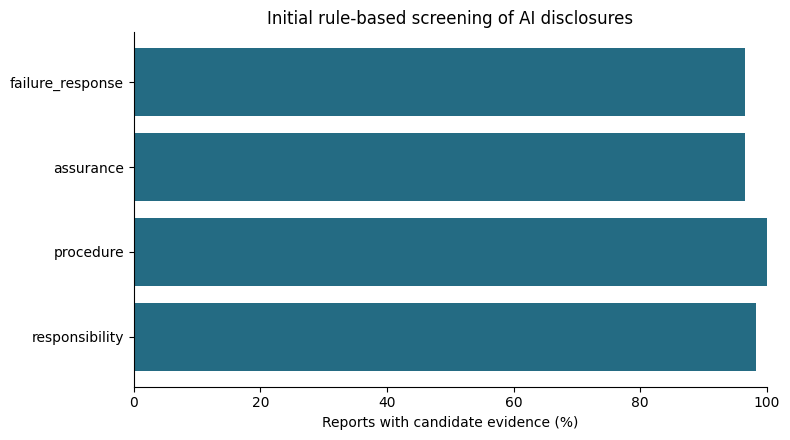

Figure saved to: C:\Users\bhavi\Downloads\Team LogicFlow\outputs\candidate_prevalence.png


In [10]:
# Create the output folder if it does not exist.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.barh(
    prevalence["dimension"],
    prevalence["flagged_share"] * 100,
    color="#246B83",
)

ax.set_xlabel("Reports with candidate evidence (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Initial rule-based screening of AI disclosures")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

image_path = OUTPUT_DIR / "candidate_prevalence.png"

fig.savefig(
    image_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(f"Figure saved to: {image_path.resolve()}")